# Homework 2 (part b): Dimensionally split finite volumes in 3D

#### Notebook Submission Deadline: Wednesday 25 November 2026 (by 9pm)

#### Homework Written Defence: Thursday 26 November 2026 (at 1pm)

#### Credits: 25 points

## Name: Silva Alejandro

## Problem 2. Dimensionally split advection in 3D

In class we solved the advection equation in 2D using **dimensional splitting**, in which one timestep is a sweep along $x$ followed by a sweep along $y$. Each of them is a 1D finite-volume (FV) solver applied along a line of cells. In this problem you will extend **nb16** to 3D:

$$\frac{\partial u}{\partial t} + c_x\frac{\partial u}{\partial x} + c_y\frac{\partial u}{\partial y} + c_z\frac{\partial u}{\partial z} = 0$$

on the periodic unit cube, so that one time-step reads:

$$u^{n+1} = \mathcal{A}_z\,\mathcal{A}_y\,\mathcal{A}_x\,u^{n}$$

where $\mathcal{A}_d$ is the 1D update of Problem 1 in direction $d$, applied line by line. The timestep is set by the fastest direction,

$$\Delta t = {\rm CFL}\;\min\left(\frac{\Delta x}{\left|c_x\right|},\ \frac{\Delta y}{\left|c_y\right|},\ \frac{\Delta z}{\left|c_z\right|}\right)$$

This is how production hydrodynamic codes advance a multi-dimensional problem, and it is the reason why a 1D solver is worth writing carefully.

### Coding tasks:

#### 3D solver construction:

**(a)** Build the solver using either **python functions or python classes**. The solver should store $u(x, y, z)$ with ghost cells on all 6 faces and perform one split time-step: an $x$-sweep over every $(j, k)$ line, a $y$-sweep over every $(i, k)$ line, and a $z$-sweep over every $(i, j)$ line. You may re-use the 1D sweep of Problem 1, including its limiter argument, and fill the periodic ghost cells before each sweep. Don't forget to alternate the order of the sweeps from one step to the next, or use the symmetric Strang ordering, and state which one you chose and why.

In [1]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import pyvista as pv
import time
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display
from fileinput import filename
from importlib.metadata import files

from matplotlib.pyplot import grid


# Plot style
import scienceplots
plt.style.use(['science', 'notebook', 'no-latex'])

# Readable fonts and a light grid in every figure
plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.alpha": 0.4, "grid.linestyle": "--"})

In [2]:
# 1D Solver class (adapted from Problem 1)
class LAdvection1D:
    '''
    Finite-volume solver for the linear 1D advection equation on a periodic domain, with a limited slope.
    '''
    # ------------------------------------------------------------------
    # Grid, initial conditions and boundary conditions
    # ------------------------------------------------------------------
    def __init__(self, nx, limiter, c=1.0, xmin=0.0, xmax=1.0, ng=2):
        # Interior cells
        self.nx = nx
        # Ghost cells
        self.ng = ng
        # Advection speed
        self.c = c
        # Left edge of the domain
        self.xmin = xmin
        # Right edge of the domain
        self.xmax = xmax
        # Limiter
        self.limiter = limiter
        # Index of the first interior cell
        self.ilo = ng
        # Index of the last interior cell
        self.ihi = ng + nx - 1
        # Cell width
        self.dx = (xmax - xmin) / nx
        # Cell centres, including the ghost cells
        self.x = xmin + (np.arange(nx + 2*ng) - ng + 0.5) * self.dx
        # Solution vector
        self.u = np.zeros(nx + 2*ng, dtype=np.float64)
        # Current time
        self.t = 0.0
        # Number of steps taken
        self.nsteps = 0

    def set_initial_condition(self, ic_function):
        '''
        Evaluates the initial condition over the grid.
        '''
        self.ic_function = ic_function
        # Evaluate the profile at every cell centre
        self.u[:] = ic_function(self.x)
        # Keep a copy of the initial data
        self.uinit = self.u.copy()
        # Reset the clock and the step counter
        self.t = 0.0
        self.nsteps = 0

    def fill_bcs(self):
        '''
        Fills the ghost cells with periodic boundary conditions.
        '''
        # Loop over the ghost cells on each side
        for n in range(self.ng):
            # Left ghost cells copy the last interior cells
            self.u[self.ilo - 1 - n] = self.u[self.ihi - n]
            # Right ghost cells copy the first interior cells
            self.u[self.ihi + 1 + n] = self.u[self.ilo + n]

    def interior(self, v=None):
        '''
        Returns the interior cells of an array (no ghost cells)
        '''
        # Interior cells of a vector (of the solution by default)
        if v is None:
            v = self.u
        return v[self.ilo:self.ihi+1]

    # ------------------------------------------------------------------
    # Limiters psi(r)
    # ------------------------------------------------------------------
    @staticmethod
    def gradient_ratio(du_left, du_right, eps=1.0e-14):
        '''
        Computes the ratio of succesive gradients.
        '''
        # Divide by a tiny number to avoid divison by zero
        safe_du_right = np.where(np.abs(du_right) > eps, du_right, eps)
        # r = (u_i - u_{i-1}) / (u_{i+1} - u_i)
        return du_left / safe_du_right

    # Minmod limiter
    @staticmethod
    def psi_minmod(r):
        return np.maximum(0.0, np.minimum(1.0, r))

    # MC limiter
    @staticmethod
    def psi_mc(r):
        # Smallest of 2r, (1 + r)/2 and 2
        smallest = np.minimum(np.minimum(2.0 * r, 0.5 * (1.0 + r)), 2.0)
        # Negative values are cut to zero
        return np.maximum(0.0, smallest)

    # van Albada limiter
    @staticmethod
    def psi_van_albada(r):
        return np.where(r > 0.0, (r**2 + r) / (r**2 + 1.0), 0.0)

    # OSPRE limiter
    @staticmethod
    def psi_ospre(r):
        return np.where(r > 0.0, 1.5 * (r**2 + r) / (r**2 + r + 1.0), 0.0)

    # van Leer limiter
    @staticmethod
    def psi_van_leer(r):
        return (r + np.abs(r)) / (1.0 + np.abs(r))

    # UMIST limiter
    @staticmethod
    def psi_umist(r):
        # First smallest
        smallest = np.minimum(2.0 * r, 0.25 * (1.0 + 3.0 * r))
        # Second smallest
        smallest = np.minimum(smallest, 0.25 * (3.0 + r))
        # Final smallest
        smallest = np.minimum(smallest, 2.0)
        # Negative values are cut to zero
        return np.maximum(0.0, smallest)

    @classmethod
    def limiters(cls):
        '''
        Returns the six limiters in a dictionary.
        Plots, runs and tables loop over this dictionary, so a new limiter only needs to be added here.
        '''
        # The six limiter functions, by name
        return {"minmod": cls.psi_minmod, "MC": cls.psi_mc, "van Albada": cls.psi_van_albada,
                "OSPRE": cls.psi_ospre, "van Leer": cls.psi_van_leer, "UMIST": cls.psi_umist}

    @classmethod
    def schemes(cls):
        '''
        Organizes the eight schemes (Godunov, centred and the six limiters) in a single dictionary that can be accessed easily.
        '''
        all_schemes = {"Godunov": "godunov", "centred": "centred"}
        all_schemes.update(cls.limiters())
        return all_schemes

    # ------------------------------------------------------------------
    # Update step: slope -> interface states -> Riemann -> update
    # ------------------------------------------------------------------
    def slopes(self):
        '''
        Computes the slope in every cell, using the chosen limiter.
        '''
        # Empty vector for the slope (Delta u / Delta x) in each cell
        slope = np.zeros_like(self.u)
        ## Godunov: zero slope
        if isinstance(self.limiter, str) and self.limiter == "godunov":
            return slope

        ## Gradients
        # Left difference for cells 1 ... N-2
        du_left = self.u[1:-1] - self.u[:-2]
        # Right difference for cells 1 ... N-2
        du_right = self.u[2:] - self.u[1:-1]

        ## Unlimited centred difference (u_{i+1} - u_{i-1}) / (2 dx)
        if isinstance(self.limiter, str) and self.limiter == "centred":
            slope[1:-1] = 0.5 * (du_left + du_right) / self.dx
            return slope

        ## Any limiter: slope = psi(r) (u_{i+1} - u_i) / dx
        r = self.gradient_ratio(du_left, du_right)
        slope[1:-1] = self.limiter(r) * du_right / self.dx
        return slope

    def interface_states(self, dt):
        '''
        Computes the left and right states at every interface, predicted to t^{n+1/2} from the slope.
        '''
        # Short names to keep the formulas readable
        ilo, ihi, dx = self.ilo, self.ihi, self.dx
        # Courant number of this step
        C = self.c * dt / dx
        # Limited slope in every cell
        slope = self.slopes()
        # Empty vectors for the left and right states; index i means interface i-1/2
        ul = np.zeros_like(self.u)
        ur = np.zeros_like(self.u)
        # Left state at i-1/2: from cell i-1, moved to its right edge
        ul[ilo:ihi+2] = self.u[ilo-1:ihi+1] + 0.5 * dx * (1.0 - C) * slope[ilo-1:ihi+1]
        # Right state at i-1/2: from cell i, moved to its left edge
        ur[ilo:ihi+2] = self.u[ilo:ihi+2] - 0.5 * dx * (1.0 + C) * slope[ilo:ihi+2]
        return ul, ur

    def riemann(self, ul, ur):
        # Upwinding: for c > 0 the information comes from the left state
        if self.c > 0.0:
            return self.c * ul
        # For c < 0 it comes from the right state
        return self.c * ur

    def conservative_update(self, dt, flux):
        # Short names
        ilo, ihi = self.ilo, self.ihi
        # Conservative update where F_{i-1/2} = flux[i]
        self.u[ilo:ihi+1] = self.u[ilo:ihi+1] + dt / self.dx * (flux[ilo:ihi+1] - flux[ilo+1:ihi+2])

    def advance(self, dt):
        '''
        One finite-volume step.
        '''
        # 1. Periodic boundary conditions
        self.fill_bcs()
        # 2. Interface states from the limited slope
        ul, ur = self.interface_states(dt)
        # 3. Riemann problem (u pwind flux)
        flux = self.riemann(ul, ur)
        # 4. Conservative update
        self.conservative_update(dt, flux)
        # 5. Advance and count the step
        self.t += dt
        self.nsteps += 1
    
    # ------------------------------------------------------------------
    # Figures
    # ------------------------------------------------------------------
    # One colour, line style and line width per scheme, used in every figure
    STYLES = {
        "Godunov":    dict(color="0.45", ls=":", lw=2.6),
        "centred":    dict(color="tab:olive", ls="--", lw=2.4),
        "minmod":     dict(color="tab:red", ls="-", lw=3.0),
        "MC":         dict(color="tab:blue", ls="-", lw=2.6),
        "van Albada": dict(color="tab:green", ls="-.", lw=2.3),
        "OSPRE":      dict(color="tab:purple", ls="--", lw=2.0),
        "van Leer":   dict(color="tab:orange", ls="-.", lw=1.8),
        "UMIST":      dict(color="tab:brown", ls=(0, (5, 1, 1, 1)), lw=1.5),
    }

In [3]:
# 3D Solver class
class LAdvection3D:
    '''
    Dimensionally split finite-volume solver for the linear 3D advection equation on the periodic unit cube.
    Every sweep is done by the 1D solver of Problem 1.
    '''
    # Same colours, line styles and widths
    STYLES = LAdvection1D.STYLES

    # ------------------------------------------------------------------
    # Grid, initial conditions and diagnostics
    # ------------------------------------------------------------------
    def __init__(self, n, limiter, c=(1.0, 1.0, 1.0), ng=2):
        # Number of interior cells per direction (same in x, y and z)
        self.n = n
        # Number of ghost cells on each of the 6 faces
        self.ng = ng
        # Limiter: "godunov", "centred", or a function psi(r)
        self.limiter = limiter
        # Advection speed in each direction
        self.cx, self.cy, self.cz = c
        # Index of the first and last interior cell (same in every direction)
        self.ilo = ng
        self.ihi = ng + n - 1
        # Cell size (unit cube, so dx = dy = dz)
        self.dx = 1.0 / n
        self.dy = 1.0 / n
        self.dz = 1.0 / n
        # Cell centres along each direction, including the ghost cells
        self.x = (np.arange(n + 2*ng) - ng + 0.5) * self.dx
        self.y = (np.arange(n + 2*ng) - ng + 0.5) * self.dy
        self.z = (np.arange(n + 2*ng) - ng + 0.5) * self.dz
        # 3D arrays of the cell-centre coordinates, indexed [i, j, k]
        self.X, self.Y, self.Z = np.meshgrid(self.x, self.y, self.z, indexing="ij")
        # Solution u[i, j, k] with ghost cells on all 6 faces
        self.u = np.zeros((n + 2*ng, n + 2*ng, n + 2*ng), dtype=np.float64)
        # One 1D solver of Problem 1 per direction: it does every sweep along that direction
        self.line_solvers = {"x": LAdvection1D(n, limiter, c=self.cx, ng=ng),
                             "y": LAdvection1D(n, limiter, c=self.cy, ng=ng),
                             "z": LAdvection1D(n, limiter, c=self.cz, ng=ng)}
        # Current time, number of steps and history of the total mass
        self.t = 0.0
        self.nsteps = 0
        self.mass_history = []

    @staticmethod
    def top_hat(X, Y, Z):
        # 1 inside a sphere of radius 0.15 centred on the cube, 0 outside
        r2 = (X - 0.5)**2 + (Y - 0.5)**2 + (Z - 0.5)**2
        return np.where(r2 <= 0.15**2, 1.0, 0.0)

    @staticmethod
    def gaussian(X, Y, Z):
        # 3D Gaussian centred on the cube
        r2 = (X - 0.5)**2 + (Y - 0.5)**2 + (Z - 0.5)**2
        return np.exp(-60.0 * r2)

    @classmethod
    def initial_conditions(cls):
        '''
        Calls the two initial profiles of the problem, keyed by name.
        '''
        return {"top hat": cls.top_hat, "Gaussian": cls.gaussian}

    @classmethod
    def schemes(cls):
        '''
        Organizes the four schemes of this problem (Godunov, MC and two of the new limiters) in a single dictionary.
        '''
        # The six limiter functions of Problem 1
        lim = LAdvection1D.limiters()
        # Godunov (string), MC and two of the limiters added in Problem 1
        return {"Godunov": "godunov", "MC": lim["MC"], "van Leer": lim["van Leer"], "van Albada": lim["van Albada"]}

    # Evaluate the initial condition on the grid
    def set_initial_condition(self, ic_function):
        # Store the profile function
        self.ic_function = ic_function
        # Evaluate the profile at every cell centre
        self.u[:] = ic_function(self.X, self.Y, self.Z)
        # Keep a copy of the initial data
        self.uinit = self.u.copy()
        # Reset the clock and the step counter
        self.t = 0.0
        self.nsteps = 0
        # Mass history starts with the initial mass
        self.mass_history = [(0.0, self.mass())]

    # Return the interior cells of a 3D array (no ghost cells)
    def interior(self, v=None):
        # Solution by default
        if v is None:
            v = self.u
        # Interior index range, the same in the three directions
        inner = slice(self.ilo, self.ihi + 1)
        return v[inner, inner, inner]

    def centre_slice(self, v=None):
        '''
        Slice of a 3D array at z = 1/2. For an even n no cell centre lies at z = 1/2,
        so the two middle planes are averaged.
        '''
        # Interior cells only
        vi = self.interior(v)
        # Index of the plane just above z = 1/2
        m = self.n // 2
        # Even n: average of the planes on each side of z = 1/2
        if self.n % 2 == 0:
            return 0.5 * (vi[:, :, m - 1] + vi[:, :, m])
        # Odd n: the middle plane is exactly at z = 1/2
        return vi[:, :, m]

    def centre_line(self, v=None):
        '''
        Line of a 3D array along x at y = z = 1/2 (interpolated).
        '''
        # Slice at z = 1/2
        plane = self.centre_slice(v)
        # Index of the line just above y = 1/2
        m = self.n // 2
        # Even n: average of the lines on each side of y = 1/2
        if self.n % 2 == 0:
            return 0.5 * (plane[:, m - 1] + plane[:, m])
        # Odd n: the middle line is exactly at y = 1/2
        return plane[:, m]

    def mass(self):
        '''
        Total mass M = sum of u dx dy dz over the interior cells.
        '''
        return np.sum(self.interior()) * self.dx * self.dy * self.dz

    # ------------------------------------------------------------------
    # One split time step: x-, y- and z-sweeps
    # ------------------------------------------------------------------
    def timestep(self, cfl):
        '''
        Time step set by the fastest direction: dt = CFL min(dx/|cx|, dy/|cy|, dz/|cz|).
        '''
        return cfl * min(self.dx / abs(self.cx), self.dy / abs(self.cy), self.dz / abs(self.cz))

    def sweep(self, direction, dt):
        '''
        1D update of Problem 1 along one direction, applied to every interior line of the cube at once.
        '''
        # Interior index range and full range (with ghost cells)
        inner = slice(self.ilo, self.ihi + 1)
        full = slice(None)
        # Block of lines along the sweep direction: full range there, interior range in the other two
        if direction == "x":
            block = self.u[full, inner, inner]
            axis = 0
        elif direction == "y":
            block = self.u[inner, full, inner]
            axis = 1
        else:
            block = self.u[inner, inner, full]
            axis = 2
        # 1D solver of this direction
        line = self.line_solvers[direction]
        # Reorder the axes so the sweep direction comes first
        line.u = np.moveaxis(block, axis, 0)
        # Update all lines at once,line.u shares memory with self.u, so the cube is updated directly

        line.advance(dt)

    def advance(self, dt):
        '''
        One split time step. The order of the sweeps alternates: x, y, z on even steps and z, y, x on odd steps.
        '''
        # Order of the sweeps for this step
        if self.nsteps % 2 == 0:
            order = ["x", "y", "z"]
        else:
            order = ["z", "y", "x"]
        # The three sweeps, each starting from the state left by the previous one
        for direction in order:
            self.sweep(direction, dt)
        # Advance the clock and count the step
        self.t += dt
        self.nsteps += 1
        # Record the total mass after the step
        self.mass_history.append((self.t, self.mass()))

    def step(self, cfl, t_stop):
        '''
        One time step at fixed CFL, shortened if needed so that it does not go past t_stop.
        '''
        # Time step from the CFL number
        dt = self.timestep(cfl)
        # Shorten it so that we land exactly on t_stop
        if self.t + dt > t_stop:
            dt = t_stop - self.t
        # Take the step
        self.advance(dt)

    def evolve(self, tmax, cfl):
        '''
        Advances the solution from the current time to tmax, at fixed CFL number.
        '''
        while self.t < tmax:
            self.step(cfl, tmax)

    # ------------------------------------------------------------------
    # Exact solution and errors
    # ------------------------------------------------------------------
    def exact(self):
        '''
        Exact solution at the current time: u(x, y, z, t) = u0(x - cx t, y - cy t, z - cz t), periodic.
        '''
        # Starting positions, wrapped into the unit cube
        X0 = np.mod(self.X - self.cx * self.t, 1.0)
        Y0 = np.mod(self.Y - self.cy * self.t, 1.0)
        Z0 = np.mod(self.Z - self.cz * self.t, 1.0)
        # Initial profile evaluated at the starting positions
        return self.ic_function(X0, Y0, Z0)

    def errors(self):
        '''
        L1 and L2 errors against the exact solution, summed over the whole cube (interior cells).
        '''
        # Difference between the numerical and the exact solution
        diff = self.interior() - self.interior(self.exact())
        # Number of interior cells, N = n^3
        N = diff.size
        # E1 = (1/N) sum |u - u_exact|
        E1 = np.sum(np.abs(diff)) / N
        # E2 = [(1/N) sum (u - u_exact)^2]^(1/2)
        E2 = np.sqrt(np.sum(diff**2) / N)
        return E1, E2

    # ------------------------------------------------------------------
    # Runners
    # ------------------------------------------------------------------
    @classmethod
    def run(cls, n, ic_function, limiter, cfl=0.4, num_periods=1):
        '''
        Builds a solver, sets the initial condition and evolves it for num_periods periods.
        Returns the finished solver, with its wall-clock time in solver.wall_time.
        '''
        # New solver
        solver = cls(n, limiter)
        # Set the initial condition
        solver.set_initial_condition(ic_function)
        # One period: time to cross the unit cube along x, which is the same along y and z
        period = 1.0 / abs(solver.cx)
        # Evolve and measure the wall-clock time
        start = time.perf_counter()
        solver.evolve(num_periods * period, cfl)
        solver.wall_time = time.perf_counter() - start
        return solver

    @classmethod
    def run_all(cls, n, cfl=0.4, num_periods=1):
        '''
        Runs the four schemes for both initial conditions.
        Returns a nested dictionary runs[ic_name][scheme_name] of finished solvers.
        '''
        # Dictionary to store the finished solvers
        runs = {}
        # Loop over the two initial conditions
        for ic_name, ic in cls.initial_conditions().items():
            runs[ic_name] = {}
            # Loop over the four schemes
            for name, lim in cls.schemes().items():
                # Run and store
                runs[ic_name][name] = cls.run(n, ic, lim, cfl, num_periods)
                # Progress report
                print("%-9s %-11s n = %3d: %4d steps in %6.1f s"
                      % (ic_name, name, n, runs[ic_name][name].nsteps, runs[ic_name][name].wall_time))
        return runs

    @classmethod
    def convergence(cls, n_list, cfl=0.4, num_periods=1):
        '''
        Runs the four schemes for both initial conditions at every n in n_list.
        Output:
          Nested dictionary conv[ic_name][scheme_name] of arrays, one row (E1, E2, seconds per step) per n.
        '''
        # Dictionary to store the errors and cost
        conv = {}
        # Loop over the two initial conditions
        for ic_name, ic in cls.initial_conditions().items():
            # Empty dictionary for this initial condition
            conv[ic_name] = {}
            # Loop over the four schemes
            for name, lim in cls.schemes().items():
                # One row per resolution
                rows = []
                for n in n_list:
                    # Run at this resolution
                    s = cls.run(n, ic, lim, cfl, num_periods)
                    # Errors and cost per step
                    E1, E2 = s.errors()
                    # Store the errors and the time of one step
                    rows.append([E1, E2, s.wall_time / s.nsteps])
                # Turn the rows into an array: one row per n, three columns
                conv[ic_name][name] = np.array(rows)
                print(ic_name, name, "...done")
        return conv

    # ------------------------------------------------------------------
    # Tables
    # ------------------------------------------------------------------
    @classmethod
    def error_table(cls, runs):
        '''
        Table of the L1 and L2 errors of each scheme, for both initial conditions.
        '''
        # One row per scheme
        rows = []
        for name in cls.schemes():
            # New row for this scheme
            row = {"scheme": name}
            # Loop over the two profiles, with a short name for the columns
            for ic_name, short in [("top hat", "hat"), ("Gaussian", "gauss")]:
                # Errors of this run
                E1, E2 = runs[ic_name][name].errors()
                row[short + " E1"] = E1
                row[short + " E2"] = E2
            rows.append(row)
        # Build the table
        return pd.DataFrame(rows).set_index("scheme").style.format("{:.2e}")

    @classmethod
    def cost_table(cls, conv, n_list, ic_name="Gaussian", scheme="MC", ng=2):
        '''
        Computes the memory of the solution array and measured cost per step at every resolution\
              for the Gaussian profile with the MC limiter.
        '''
        # One row per resolution
        rows = []
        for k, n in enumerate(n_list):
            rows.append({"n": n,
                         # Number of interior cells
                         "cells n^3": n**3,
                         # Memory of u, ghost cells included, in MB (8 bytes per value)
                         "memory of u [MB]": (n + 2*ng)**3 * 8 / 1.0e6,
                         # Wall-clock time of one split step
                         "time per step [s]": conv[ic_name][scheme][k, 2]})
        return pd.DataFrame(rows).set_index("n").round(4)

    # ------------------------------------------------------------------
    # Figures
    # ------------------------------------------------------------------
    @classmethod
    def plot_slices(cls, runs, ic_name):
        '''
        Slices at z = 1/2, one row per scheme: the exact solution (left) beside the scheme (right), on a common colour scale.
        '''
        # Names of the four schemes, one per row
        names = list(cls.schemes())
        # Exact and numerical slices of each scheme at its final time
        exact_slices = [runs[ic_name][name].centre_slice(runs[ic_name][name].exact()) for name in names]
        num_slices = [runs[ic_name][name].centre_slice() for name in names]
        # Common colour scale for all panels
        vmin = min(f.min() for f in exact_slices + num_slices)
        vmax = max(f.max() for f in exact_slices + num_slices)
        # One row per scheme, two columns: exact (left) and scheme (right)
        fig, axes = plt.subplots(len(names), 2, figsize=(9, 4.0 * len(names)), constrained_layout=True)
        # Loop over the rows
        for row, name in enumerate(names):
            # Final time of this run
            t = runs[ic_name][name].t
            # Left panel: exact solution; right panel: the scheme
            panels = [(axes[row, 0], exact_slices[row], "exact, $t = %.2f$" % t),
                      (axes[row, 1], num_slices[row], "%s, $t = %.2f$" % (name, t))]
            for ax, field, title in panels:
                # Transpose so that x runs horizontally and y vertically
                im = ax.imshow(field.T, origin="lower", extent=[0, 1, 0, 1], cmap="viridis", vmin=vmin, vmax=vmax)
                ax.set_title(title)
                ax.set_xlabel(r"$x$")
                ax.set_ylabel(r"$y$")
                ax.grid(False)
        # One colour bar for the whole figure
        fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6, label=r"$u$")
        fig.suptitle(r"%s: slice $z = 1/2$, $n = %d$, CFL = 0.4, one period" % (ic_name, runs[ic_name][names[0]].n))
        plt.show()

    @classmethod
    def plot_axis(cls, runs):
        '''
        Profiles along the axis y = z = 1/2 for the four schemes and the exact solution, one panel per profile.
        '''
        # One panel per initial condition
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
        for ax, ic_name in zip(axes, cls.initial_conditions()):
            # Any run gives the grid and the exact solution
            s0 = runs[ic_name]["Godunov"]
            # Interior cell centres along x
            x = s0.x[s0.ilo:s0.ihi + 1]
            # Exact solution along the axis
            ax.plot(x, s0.centre_line(s0.exact()), "k-", lw=1.0, label="exact")
            # The four schemes
            for name in cls.schemes():
                ax.plot(x, runs[ic_name][name].centre_line(), label=name, **cls.STYLES[name])
            ax.set_xlabel(r"$x$")
            ax.set_ylabel(r"$u(x, 1/2, 1/2)$")
            ax.set_title("%s along $y = z = 1/2$, $n = %d$" % (ic_name, s0.n))
            ax.legend(fontsize=10)
        plt.tight_layout()
        plt.show()

    @classmethod
    def plot_convergence(cls, conv, n_list):
        '''
        Log-log plots of E1 and E2 against n for the four schemes, with reference slopes -1 and -2.
        The measured order p is the straight-line fit on all resolutions.
        '''
        # Figure
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        # Array of all the resolutions
        n_list = np.asarray(n_list)
        # Loop over the two profiles (rows)
        for row, ic_name in enumerate(conv):
            # Loop over the two norms (columns)
            for col, norm in enumerate([r"$E_1$", r"$E_2$"]):
                # Begin a panel
                ax = axes[row, col]
                # Loop over the four schemes
                for name in cls.schemes():
                    # Errors of this scheme in this norm, one per n
                    err = conv[ic_name][name][:, col]
                    # Order p: minus the slope of log(E) vs log(n)
                    p = -np.polyfit(np.log(n_list), np.log(err), 1)[0]
                    # Error curve
                    ax.loglog(n_list, err, marker="o", ms=5, label="%s (p = %.2f)" % (name, p), **cls.STYLES[name])
                # Errors at the coarsest grid, to place the reference lines
                e0 = [conv[ic_name][name][0, col] for name in cls.schemes()]
                # Reference slope -1, starting above all curves
                ax.loglog(n_list, 1.5 * max(e0) * (n_list / n_list[0])**-1.0, "k--", lw=1.0, label="slope $-1$")
                # Reference slope -2, starting below all curves
                ax.loglog(n_list, 0.6 * min(e0) * (n_list / n_list[0])**-2.0, "k:", lw=1.4, label="slope $-2$")
                # Ticks at the resolutions used
                ax.set_xticks(n_list)
                ax.set_xticklabels([str(n) for n in n_list])
                ax.minorticks_off()
                # Labels
                ax.set_xlabel(r"$n$")
                ax.set_ylabel(norm)
                ax.set_title("%s, %s, one period, CFL = 0.4" % (ic_name, norm))
                ax.legend(fontsize=10, loc="lower left")
        plt.tight_layout()
        plt.show()

    @classmethod
    def plot_mass_drift(cls, runs, tol=1.0e-12):
        '''
        Relative mass drift [M(t) - M(0)] / M(0) against time, one curve per scheme, one panel per profile.
        The y axis is fixed to +-tol.
        '''
        # One panel per initial condition
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
        for ax, ic_name in zip(axes, cls.initial_conditions()):
            for name in cls.schemes():
                # Times and masses recorded after every step
                t, M = np.array(runs[ic_name][name].mass_history).T
                # Relative drift with respect to the initial mass
                drift = (M - M[0]) / M[0]
                # Curve, with the largest drift in the legend
                ax.plot(t, drift, label="%s (max %.1e)" % (name, np.abs(drift).max()), **cls.STYLES[name])
            # Fixed y axis
            ax.set_ylim(-tol, tol)
            ax.set_xlabel(r"$t$")
            ax.set_ylabel(r"$[M(t) - M(0)]\,/\,M(0)$")
            ax.set_title("%s: relative mass drift" % ic_name)
            ax.legend(fontsize=10, loc="upper left")
        plt.tight_layout()
        plt.show()

    # ------------------------------------------------------------------
    # Output for ParaView
    # ------------------------------------------------------------------
    @staticmethod
    def write_vtr(filename, x, y, z, u):
        '''
        Writes a cell-centred field u[i, j, k] to a VTK rectilinear grid file (.vtr), readable by VisIt and ParaView.
        x, y, z are the cell centres; the grid is built on the cell edges.
        '''
        # Get cell edges from the cell centres (uniform grid)
        def edges(c):
            h = c[1] - c[0]
            return np.append(c - 0.5 * h, c[-1] + 0.5 * h)
        # Define the rectilinear grid, whose points are the cell edges
        grid = pv.RectilinearGrid(edges(x), edges(y), edges(z))
        # Flatten u into one list with the x index changing fastest (the cell order VTK uses)
        grid.cell_data["u"] = np.ravel(u, order="F")
        # Save as .vtr
        grid.save(filename)
        

    @classmethod
    def write_snapshots(cls, n, ic_name, scheme_name, folder="vtr", nfiles=5, cfl=0.4):
        '''
        Runs one scheme for one period and writes nfiles .vtr files at equally spaced times (t = 0 ... T).
        Returns the list of file names.
        '''
        # Make a folder for the output files
        os.makedirs(folder, exist_ok=True)
        # Create the solver with the chosen scheme and profile
        s = cls(n, cls.schemes()[scheme_name])
        s.set_initial_condition(cls.initial_conditions()[ic_name])
        # Define the output times, from 0 to one period
        output_times = np.linspace(0.0, 1.0 / abs(s.cx), nfiles)
        # Define the interior cell centres (the same along the three directions)
        xc = s.x[s.ilo:s.ihi + 1]
        # Define the filename
        prefix = ic_name.replace(" ", "") + "_" + scheme_name.replace(" ", "")
        # List to save filenames
        files = []
        for k, t_out in enumerate(output_times):
            # Advance to the output time, landing exactly on it
            while s.t < t_out:
                s.step(cfl, t_out)
            # Write the interior field
            name = os.path.join(folder, "%s_%04d.vtr" % (prefix, k))
            cls.write_vtr(name, xc, xc, xc, s.interior())
            files.append(name)
        return files

    # ------------------------------------------------------------------
    # Animation
    # ------------------------------------------------------------------
    @classmethod
    def animate(cls, scheme_name, n=64, cfl=0.4, steps_per_frame=4):
        '''
        Top hat advected for one period. Each frame shows the plane z = (1/2 + cz t) mod 1,
        which follows the sphere, for the numerical and the exact solution, on a fixed colour scale [0, 1].
        '''
        # Solver with the chosen scheme and the top hat
        s = cls(n, cls.schemes()[scheme_name])
        s.set_initial_condition(cls.top_hat)
        # One period
        tmax = 1.0 / abs(s.cx)

        def plane_index():
            # Height of the plane that follows the sphere
            z_plane = np.mod(0.5 + s.cz * s.t, 1.0)
            # Interior cell that contains that height
            return min(int(z_plane / s.dz), s.n - 1), z_plane

        def frame():
            # Current time, plane, and the numerical and exact slices on that plane
            k, z_plane = plane_index()
            return s.t, z_plane, s.interior()[:, :, k].copy(), s.interior(s.exact())[:, :, k].copy()

        # First frame, then one frame every steps_per_frame steps (and the last one)
        frames = [frame()]
        while s.t < tmax:
            s.step(cfl, tmax)
            if s.nsteps % steps_per_frame == 0 or s.t >= tmax:
                frames.append(frame())

        # Figure
        fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
        # Fix margins and space for the colour bar on the right
        fig.subplots_adjust(left=0.07, right=0.86, bottom=0.12, top=0.86, wspace=0.25)
        # Axes for the colour bar, at a fixed position
        cax = fig.add_axes([0.89, 0.15, 0.02, 0.68])
        images = []
        for ax, field, title in zip(axes, frames[0][2:], [scheme_name, "exact"]):
            im = ax.imshow(field.T, origin="lower", extent=[0, 1, 0, 1], cmap="viridis", vmin=0.0, vmax=1.0)
            ax.set_xlabel(r"$x$")
            ax.set_ylabel(r"$y$")
            ax.set_title(title)
            ax.grid(False)
            images.append(im)
        # Colour bar in its fixed axes
        fig.colorbar(images[0], cax=cax, label=r"$u$")
        label = fig.suptitle("")

        def update(k):
            # Update both slices and the label of frame k
            t, z_plane, u_num, u_ex = frames[k]
            images[0].set_data(u_num.T)
            images[1].set_data(u_ex.T)
            label.set_text(r"Top hat, $n = %d$: $t = %.3f$, plane $z = %.3f$" % (n, t, z_plane))
            return images + [label]

        anim = FuncAnimation(fig, update, frames=len(frames), interval=80)
        # Close the static figure so only the GIF is shown later
        plt.close(fig)
        return anim


There is one 1D solver per direction. A sweep along $x$ takes the block `u[:, interior, interior]`, moves the $x$ axis to the front with `np.moveaxis` and hands it to the 1D solver as its `u`. We do this too for the $y$-sweep and the $z$-sweep.

We **alternate** the order: $x, y, z$ on even steps and $z, y, x$ on odd steps because single fixed order $\mathcal{A}_z\mathcal{A}_y\mathcal{A}_x$ is only first order in time, because the splitting error does not cancel. Reversing the order every step makes each pair of steps symmetric, which cancels that error and gives second order.

### **(b)** Use the 3D versions of the two profiles of Problem 1 on the unit cube, with $c_x = c_y = c_z = 1$:

$$u_{\rm hat} = \begin{cases} 1 & \left(x - 1/2\right)^{2} + \left(y - 1/2\right)^{2} + \left(z - 1/2\right)^{2} \leq \left(0.15\right)^{2} \\[3pt] 0 & {\rm otherwise}\end{cases} \qquad\qquad u_{\rm gauss} = e^{-60\left[\left(x - 1/2\right)^{2} + \left(y - 1/2\right)^{2} + \left(z - 1/2\right)^{2}\right]}$$

With $n_x = n_y = n_z = 64$ and ${\rm CFL} = 0.4$, advect both profiles for one full period, so that the exact solution is again the initial condition. Use 4 schemes: Godunov, MC, and two of the limiters you added in Problem 1.

Schemes: Godunov, MC, and two of the limiters added in Problem 1, **van Leer** and **van Albada**

In [4]:
# Run the four schemes for both profiles (prints the cost of each run)
runs_1T = LAdvection3D.run_all(n=64, cfl=0.4, num_periods=1)

top hat   Godunov     n =  64:  161 steps in    2.6 s
top hat   MC          n =  64:  161 steps in    5.6 s
top hat   van Leer    n =  64:  161 steps in    5.0 s
top hat   van Albada  n =  64:  161 steps in    5.1 s
Gaussian  Godunov     n =  64:  161 steps in    2.5 s
Gaussian  MC          n =  64:  161 steps in    5.5 s
Gaussian  van Leer    n =  64:  161 steps in    5.0 s
Gaussian  van Albada  n =  64:  161 steps in    5.0 s


### **(c)** Show the results as slices through the centre of the cube, $z = 1/2$, with the initial condition beside the final one on a common colour scale, and add one high-quality, labeled line plot along the axis $y = z = 1/2$ comparing the 4 schemes with the exact profile.

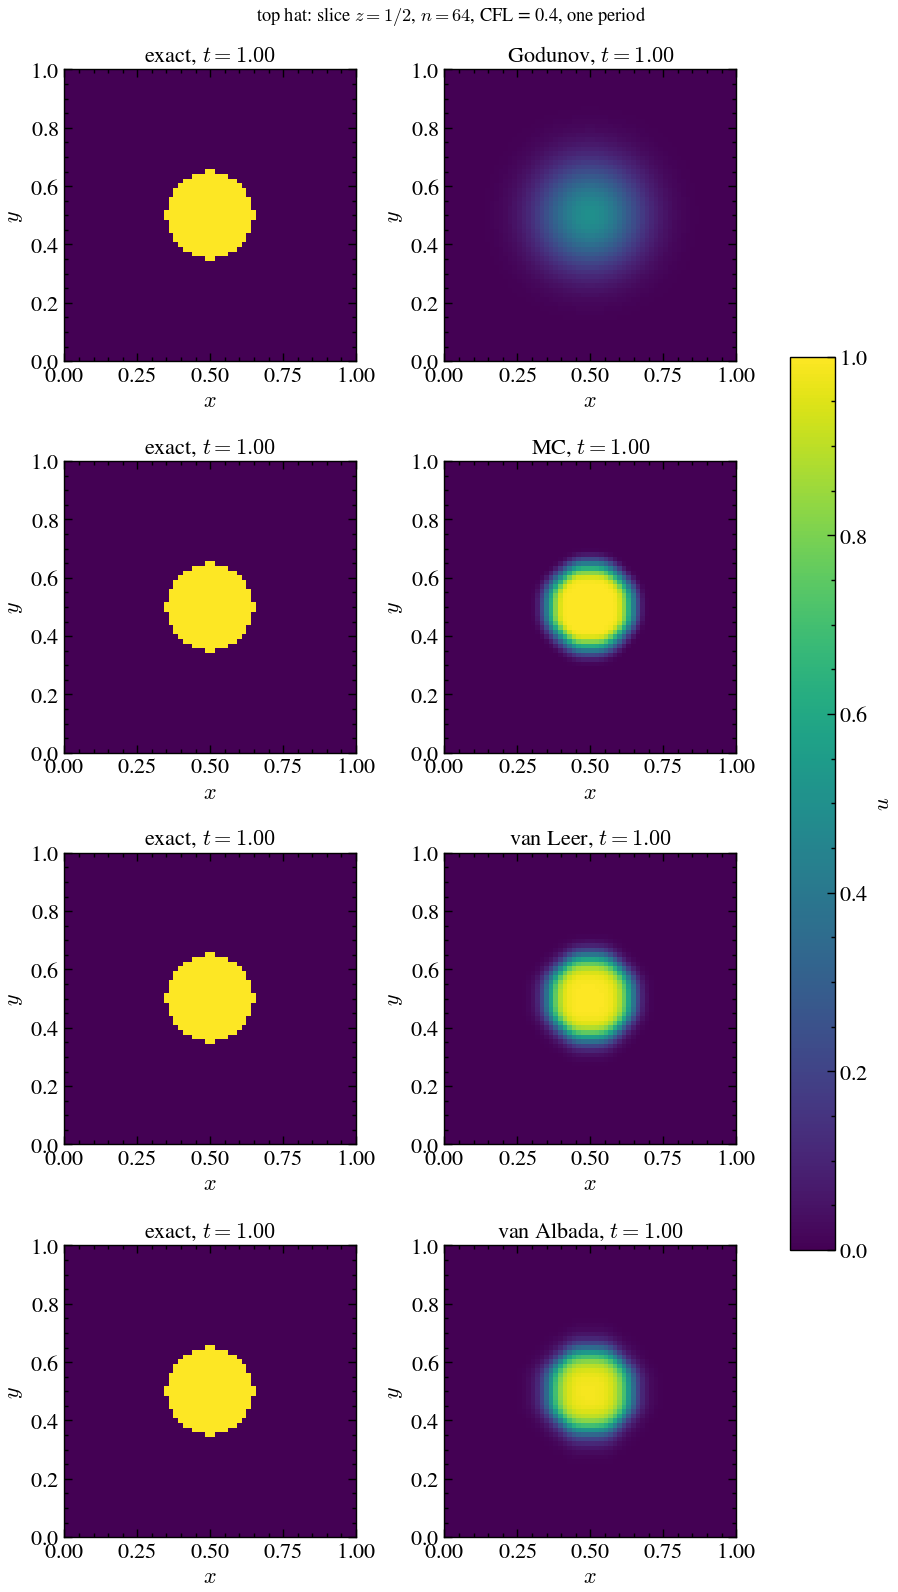

In [5]:
# Slices at z = 1/2: top hat
LAdvection3D.plot_slices(runs_1T, "top hat")

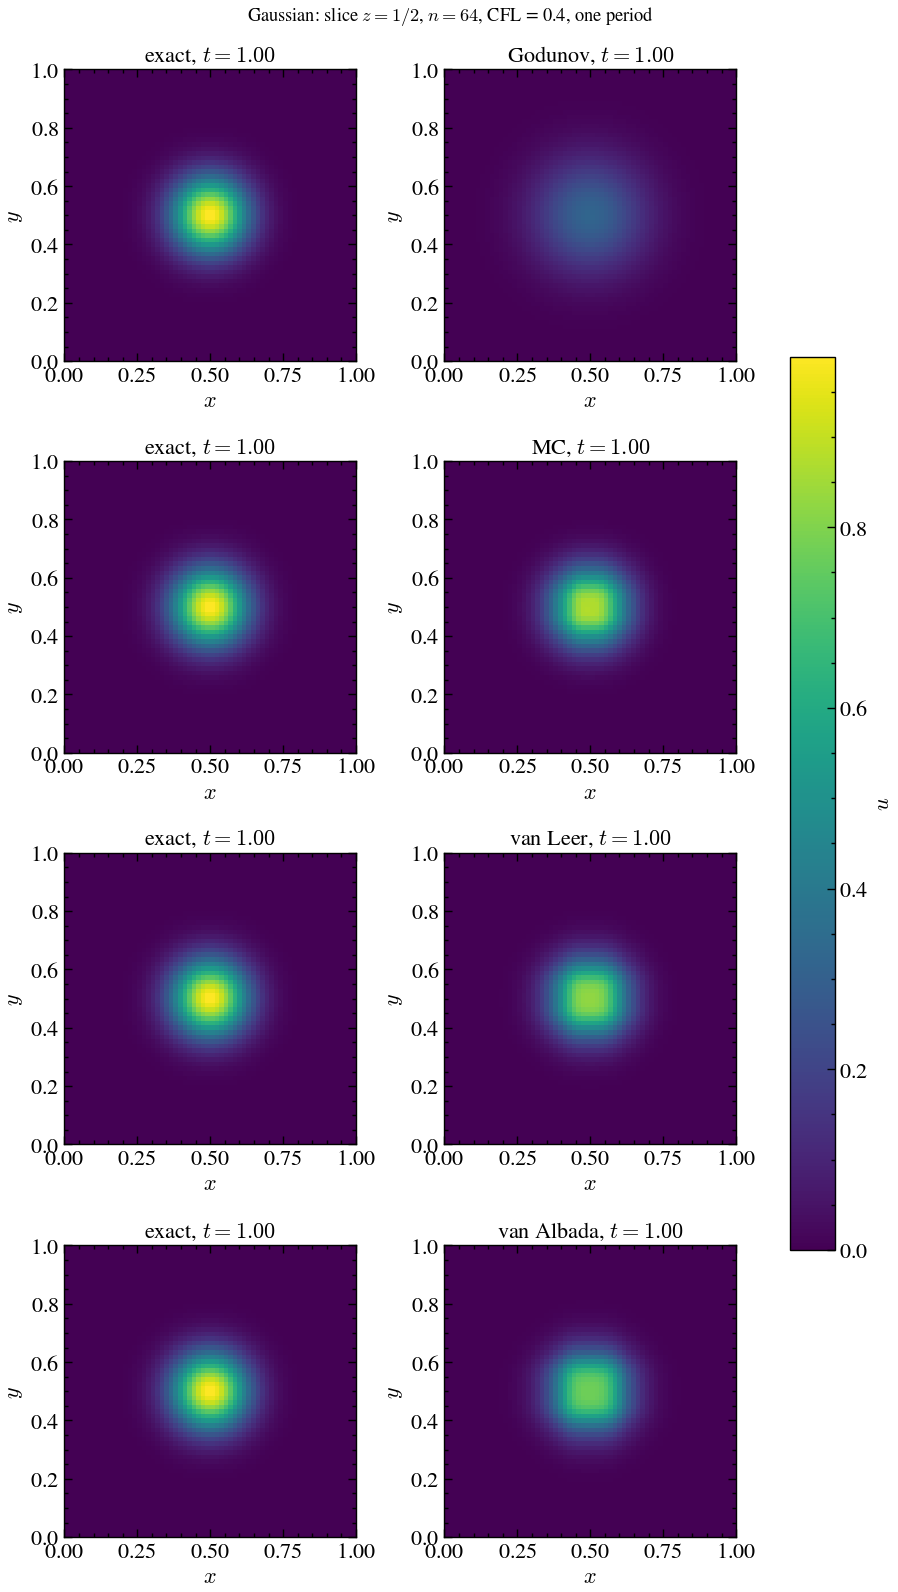

In [6]:
# Slices at z = 1/2: Gaussian
LAdvection3D.plot_slices(runs_1T, "Gaussian")

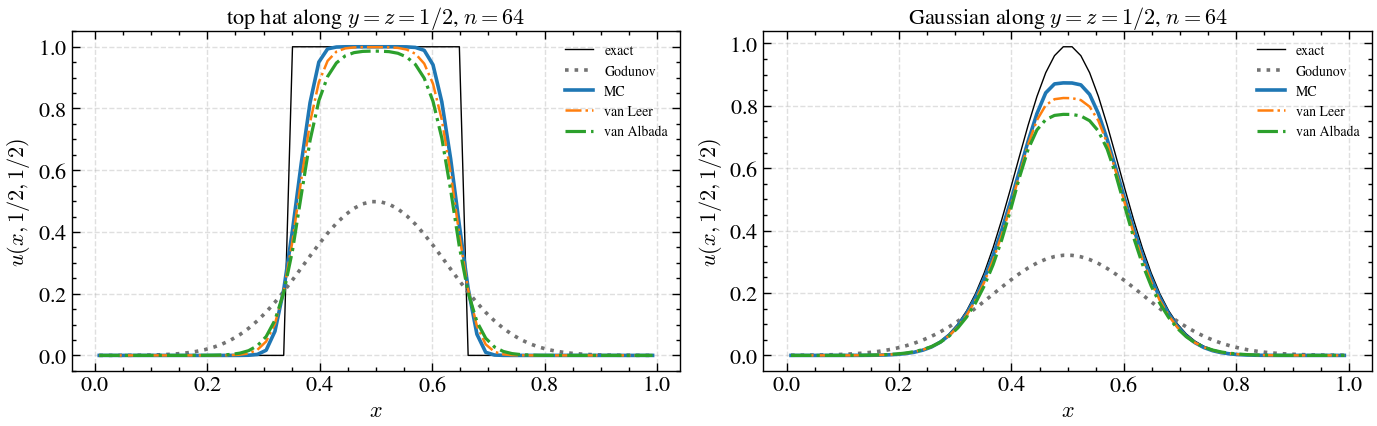

In [7]:
# Profiles along y = z = 1/2 against the exact solution
LAdvection3D.plot_axis(runs_1T)

#### Errors and conservation:

**(d)** Using the same norms as in Problem 1, now summed over the whole cube, compute $E_1$ and $E_2$ for the 4 schemes and the 2 profiles. Then repeat the runs at at least 3 resolutions, for example $n = 32$, $48$ and $64$ cells per direction, and add $96$ if your machine allows it. Make labeled log-log plots of $E_1$ and $E_2$ against $n$ for the 2 profiles, with reference lines of slope $-1$ and $-2$, as in Problem 1, and say how the measured order compares with the 1D one. 

```python
def exact(self):
    '''
    Exact solution at the current time: u(x, y, z, t) = u0(x - cx t, y - cy t, z - cz t), periodic.
    '''
    # Starting positions, wrapped into the unit cube
    X0 = np.mod(self.X - self.cx * self.t, 1.0)
    Y0 = np.mod(self.Y - self.cy * self.t, 1.0)
    Z0 = np.mod(self.Z - self.cz * self.t, 1.0)
    # Initial profile evaluated at the starting positions
    return self.ic_function(X0, Y0, Z0)

 def errors(self):
    '''
    L1 and L2 errors against the exact solution, summed over the whole cube (interior cells).
    '''
    # Difference between the numerical and the exact solution
    diff = self.interior() - self.interior(self.exact())
    # Number of interior cells, N = n^3
    N = diff.size
    # E1 = (1/N) sum |u - u_exact|
    E1 = np.sum(np.abs(diff)) / N
    # E2 = [(1/N) sum (u - u_exact)^2]^(1/2)
    E2 = np.sqrt(np.sum(diff**2) / N)
    return E1, E2

@classmethod
def error_table(cls, runs):
    '''
    Table of the L1 and L2 errors of each scheme, for both initial conditions.
    '''
    # One row per scheme
    rows = []
    for name in cls.schemes():
        # New row for this scheme
        row = {"scheme": name}
        # Loop over the two profiles, with a short name for the columns
        for ic_name, short in [("top hat", "hat"), ("Gaussian", "gauss")]:
            # Errors of this run
            E1, E2 = runs[ic_name][name].errors()
            row[short + " E1"] = E1
            row[short + " E2"] = E2
        rows.append(row)
    # Build the table
    return pd.DataFrame(rows).set_index("scheme").style.format("{:.2e}")

@classmethod
def convergence(cls, n_list, cfl=0.4, num_periods=1):
    '''
    Runs the four schemes for both initial conditions at every n in n_list.
    Output:
        Nested dictionary conv[ic_name][scheme_name] of arrays, one row (E1, E2, seconds per step) per n.
    '''
    # Dictionary to store the errors and cost
    conv = {}
    # Loop over the two initial conditions
    for ic_name, ic in cls.initial_conditions().items():
        # Empty dictionary for this initial condition
        conv[ic_name] = {}
        # Loop over the four schemes
        for name, lim in cls.schemes().items():
            # One row per resolution
            rows = []
            for n in n_list:
                # Run at this resolution
                s = cls.run(n, ic, lim, cfl, num_periods)
                # Errors and cost per step
                E1, E2 = s.errors()
                # Store the errors and the time of one step
                rows.append([E1, E2, s.wall_time / s.nsteps])
            # Turn the rows into an array: one row per n, three columns
            conv[ic_name][name] = np.array(rows)
            print(ic_name, name, "...done")
    return conv

@classmethod
def plot_convergence(cls, conv, n_list):
    '''
    Log-log plots of E1 and E2 against n for the four schemes, with reference slopes -1 and -2.
    The measured order p is the straight-line fit on all resolutions.
    '''
    # Figure
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    # Array of all the resolutions
    n_list = np.asarray(n_list)
    # Loop over the two profiles (rows)
    for row, ic_name in enumerate(conv):
        # Loop over the two norms (columns)
        for col, norm in enumerate([r"$E_1$", r"$E_2$"]):
            # Begin a panel
            ax = axes[row, col]
            # Loop over the four schemes
            for name in cls.schemes():
                # Errors of this scheme in this norm, one per n
                err = conv[ic_name][name][:, col]
                # Order p: minus the slope of log(E) vs log(n)
                p = -np.polyfit(np.log(n_list), np.log(err), 1)[0]
                # Error curve
                ax.loglog(n_list, err, marker="o", ms=5, label="%s (p = %.2f)" % (name, p), **cls.STYLES[name])
            # Errors at the coarsest grid, to place the reference lines
            e0 = [conv[ic_name][name][0, col] for name in cls.schemes()]
            # Reference slope -1, starting above all curves
            ax.loglog(n_list, 1.5 * max(e0) * (n_list / n_list[0])**-1.0, "k--", lw=1.0, label="slope $-1$")
            # Reference slope -2, starting below all curves
            ax.loglog(n_list, 0.6 * min(e0) * (n_list / n_list[0])**-2.0, "k:", lw=1.4, label="slope $-2$")
            # Ticks at the resolutions used
            ax.set_xticks(n_list)
            ax.set_xticklabels([str(n) for n in n_list])
            ax.minorticks_off()
            # Labels
            ax.set_xlabel(r"$n$")
            ax.set_ylabel(norm)
            ax.set_title("%s, %s, one period, CFL = 0.4" % (ic_name, norm))
            ax.legend(fontsize=8, loc="lower left")
    plt.tight_layout()
    plt.show()
   
```

In [8]:
# E1 and E2 of the one-period runs at n = 64
display(LAdvection3D.error_table(runs_1T))

,hat E1,hat E2,gauss E1,gauss E2
scheme,,,,
Godunov,1.86e-02,8.53e-02,8.07e-03,3.56e-02
MC,5.30e-03,4.06e-02,3.74e-04,2.53e-03
van Leer,6.31e-03,4.33e-02,5.58e-04,4.11e-03
van Albada,7.33e-03,4.62e-02,8.51e-04,6.00e-03


top hat Godunov ...done
top hat MC ...done
top hat van Leer ...done
top hat van Albada ...done
Gaussian Godunov ...done
Gaussian MC ...done
Gaussian van Leer ...done
Gaussian van Albada ...done


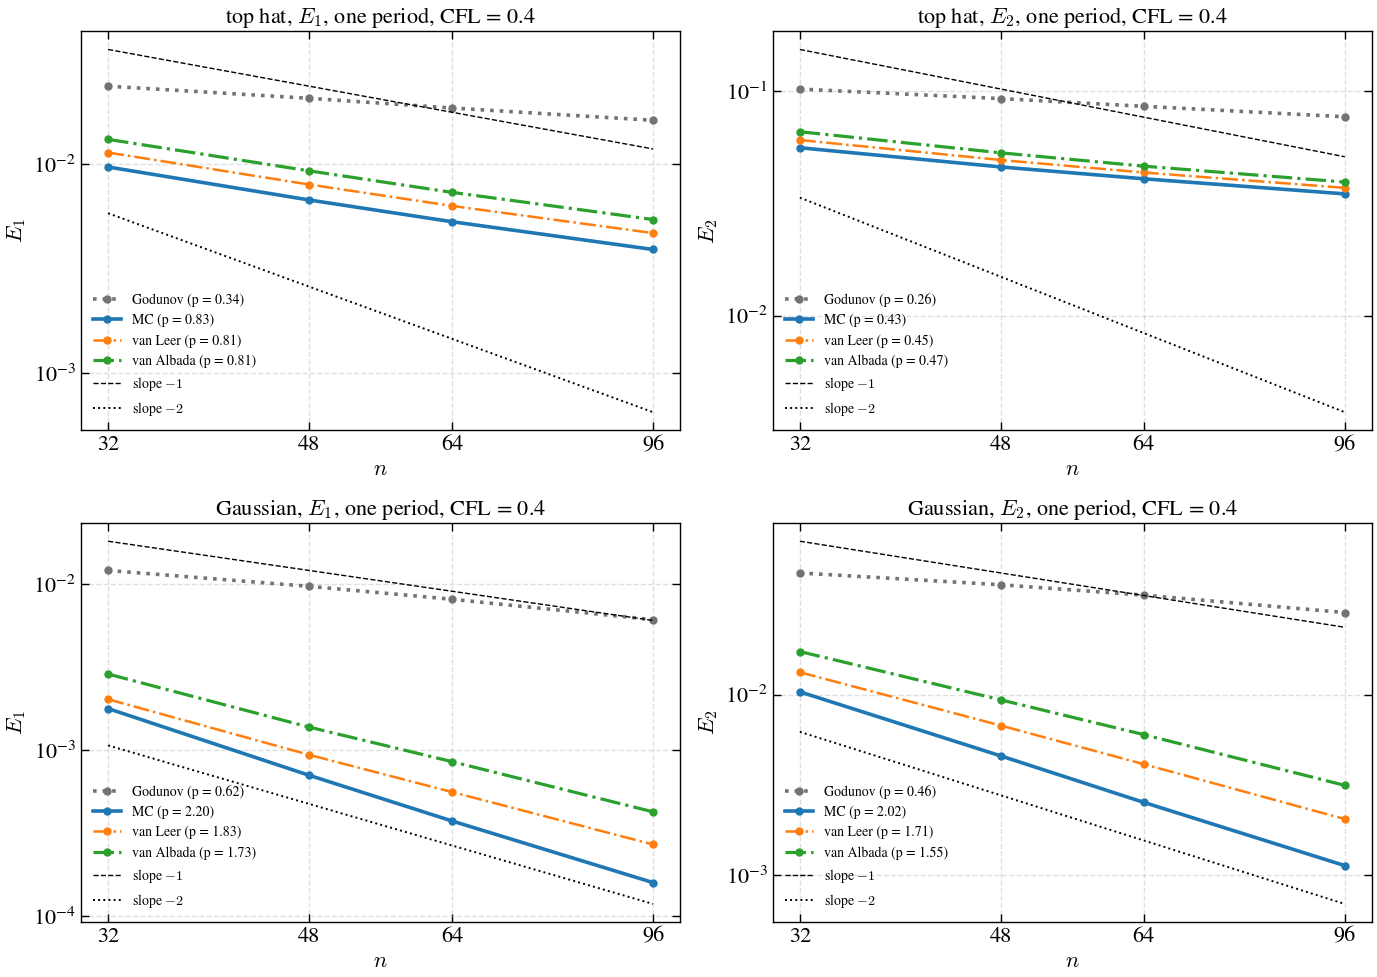

In [9]:
# Convergence study: one period at n = 32, 48, 64, 96
n_list = [32, 48, 64, 96]
conv3d = LAdvection3D.convergence(n_list, cfl=0.4, num_periods=1)
LAdvection3D.plot_convergence(conv3d, n_list)

**Comparison with the 1D order:**

The limiters keep their 1D order in 3D. So the splitting doesn't lower the order of the 1D scheme, which was expected following the alternating sweep order that kept the second order in time.
On the Gaussian, MC stays second order and van Leer and van Albada stay close to it. On the top hat no scheme approaches order 2 in either case because the error is controlled by the smeared discontinuity, here the surface of the sphere.

#### **(e)** Compute also the total mass:

$$M = \sum_{i,j,k} u_{ijk}\;\Delta x\,\Delta y\,\Delta z$$

Make one high-quality, labeled figure with the relative mass drift $\left[M(t) - M(0)\right]/M(0)$ against time, one curve per scheme. Briefly discuss what this figure tells you about the update.

```python
def mass(self):
    '''
    Total mass M = sum of u dx dy dz over the interior cells.
    '''
    return np.sum(self.interior()) * self.dx * self.dy * self.dz

@classmethod
def plot_mass_drift(cls, runs, tol=1.0e-12):
    '''
    Relative mass drift [M(t) - M(0)] / M(0) against time, one curve per scheme, one panel per profile.
    The y axis is fixed to +-tol.
    '''
    # One panel per initial condition
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, ic_name in zip(axes, cls.initial_conditions()):
        for name in cls.schemes():
            # Times and masses recorded after every step
            t, M = np.array(runs[ic_name][name].mass_history).T
            # Relative drift with respect to the initial mass
            drift = (M - M[0]) / M[0]
            # Curve, with the largest drift in the legend
            ax.plot(t, drift, label="%s (max %.1e)" % (name, np.abs(drift).max()), **cls.STYLES[name])
        # Fixed y axis
        ax.set_ylim(-tol, tol)
        ax.set_xlabel(r"$t$")
        ax.set_ylabel(r"$[M(t) - M(0)]\,/\,M(0)$")
        ax.set_title("%s: relative mass drift" % ic_name)
        ax.legend(fontsize=10, loc="upper left")
    plt.tight_layout()
    plt.show()
```

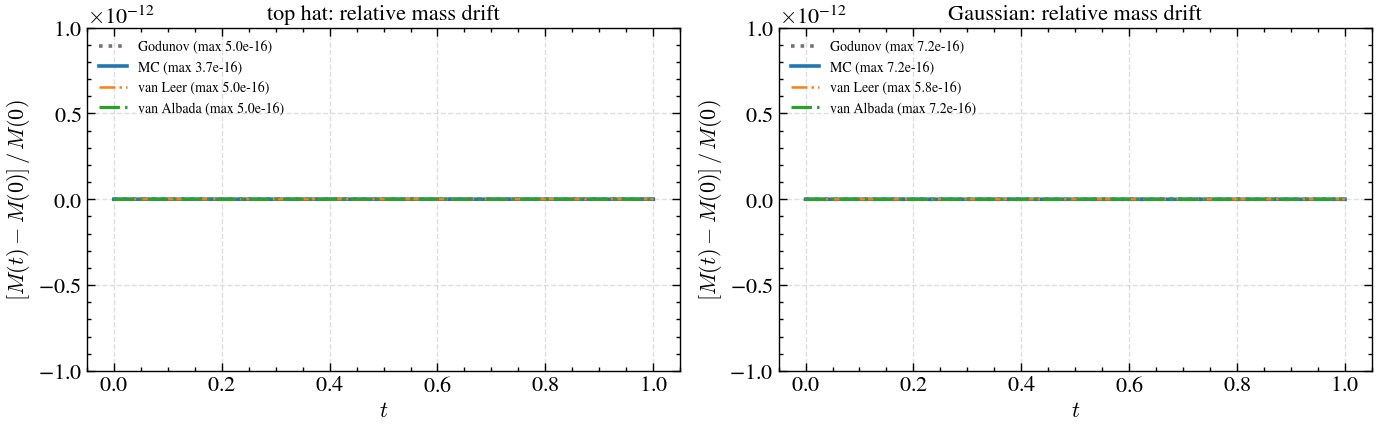

In [10]:
# Relative mass drift of the n = 64 runs
LAdvection3D.plot_mass_drift(runs_1T)

**Discussion:**

Without limiting the scale $(1e-16)$ the plot only shows round-off errors, which hide the result so we set it to $1e-12$. The scheme conserves mass to round-off because it's written in conservative form. So the sum over the cube telescopes, and with periodic boundaries nothing leaves the domain. This holds whatever slope or limiter is used.

#### Outputs for CFD visualisation packages:

**(f)** Write a function `write_vtr(filename, x, y, z, u)` that writes the field to a VTK rectilinear grid file (`.vtr`), so that the cube can be opened in **VisIt** or **ParaView**. Write 5 files per scheme at different times, open at least one of them in VisIt or ParaView, and include in the notebook a screenshot of an isosurface or rendering of the top-hat run.

```python
@staticmethod
def write_vtr(filename, x, y, z, u):
    '''
    Writes a cell-centred field u[i, j, k] to a VTK rectilinear grid file (.vtr), readable by VisIt and ParaView.
    x, y, z are the cell centres; the grid is built on the cell edges.
    '''
    # Get cell edges from the cell centres (uniform grid)
    def edges(c):
        h = c[1] - c[0]
        return np.append(c - 0.5 * h, c[-1] + 0.5 * h)
    # Degine the rectilinear grid, whose points are the cell edges
    grid = pv.RectilinearGrid(edges(x), edges(y), edges(z))
    # Flatten u into one list with the x index changing fastest (the cell order VTK uses)
    grid.cell_data["u"] = np.ravel(u, order="F")
    # Save as .vtr
    grid.save(filename)

@classmethod
def write_snapshots(cls, n, ic_name, scheme_name, folder="vtr", nfiles=5, cfl=0.4):
    '''
    Runs one scheme for one period and writes nfiles .vtr files at equally spaced times (t = 0 ... T).
    Returns the list of file names.
    '''
    # Make a folder for the output files
    os.makedirs(folder, exist_ok=True)
    # Create the solver with the chosen scheme and profile
    s = cls(n, cls.schemes()[scheme_name])
    s.set_initial_condition(cls.initial_conditions()[ic_name])
    # Define the output times, from 0 to one period
    output_times = np.linspace(0.0, 1.0 / abs(s.cx), nfiles)
    # Define the interior cell centres (the same along the three directions)
    xc = s.x[s.ilo:s.ihi + 1]
    # Define the filename
    prefix = ic_name.replace(" ", "") + "_" + scheme_name.replace(" ", "")
    # List to present the saved filenames
    files = []
    for k, t_out in enumerate(output_times):
        # Advance to the output time, landing exactly on it
        while s.t < t_out:
            s.step(cfl, t_out)
        # Write the interior field
        name = os.path.join(folder, "%s_%04d.vtr" % (prefix, k))
        cls.write_vtr(name, xc, xc, xc, s.interior())
        files.append(name)
    return files
```

In [11]:
# Five .vtr files per scheme for the top hat, in the folder vtr/
for name in LAdvection3D.schemes():
    # Run the scheme and write its files
    files = LAdvection3D.write_snapshots(64, "top hat", name, folder="vtr", nfiles=5)
    # Number of files written
    print("%-11s %d files written in vtr/" % (name, len(files)))

Godunov     5 files written in vtr/
MC          5 files written in vtr/
van Leer    5 files written in vtr/
van Albada  5 files written in vtr/


**Screenshots.**

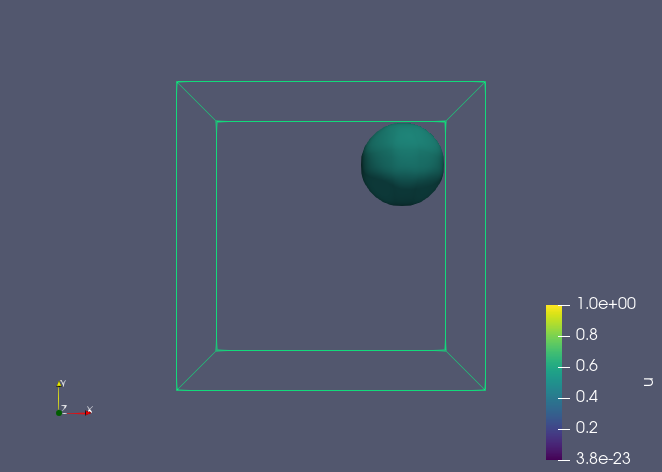
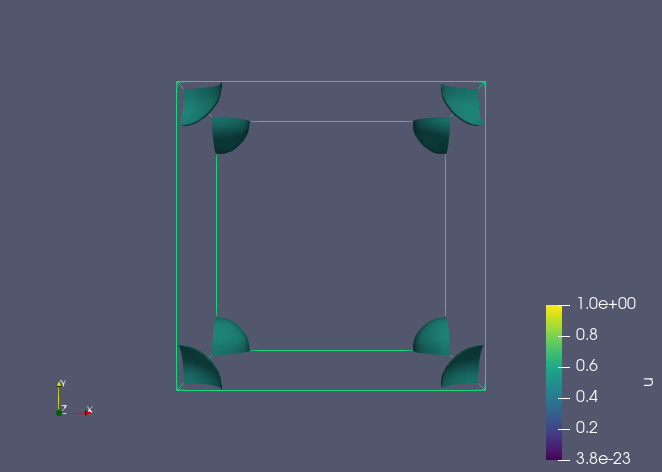
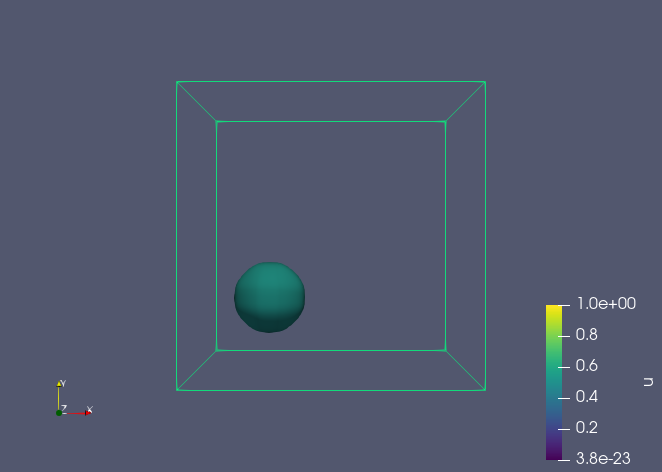

### Analysis questions:

**(g)** Answer the following questions, based on your figures and results:

#### Does the ranking of the limiters you found in 1D survive in 3D? Compare the same quantity, e.g. $E_1$ for the top hat, in both problems 1 and 2.

Yes, the ranking survives. The ranking carries over because each 3D sweep is the 1D update of Problem 1, so every limiter acts the same way along each direction. For the top hat, $E_1$ orders the three limiters the same way in both problems: MC has the smallest error, then van Leer, then van Albada. The Gaussian gives the same order.

#### The split solver never solves a Riemann problem along the diagonal of the cube, yet the profile is advected along it. Explain how the diagonal motion is produced, and what error this introduces.

Each sweep moves the profile only along its own axis. The diagonal motion is the sum of three small axis-aligned moves, like a staircase made of very small steps. Each sweep starts from the result of the previous one, and that's what couples the directions. 

Splitting adds an error that is first order in time for a fixed sweep order (reduced to second order by alternating the order), and since each sweep diffuses only along its own axis, the profile is smeared more in some directions than in others, so the sphere loses its round shape.

#### Your total mass should be conserved to round-off while the errors are large. Which property of the scheme guarantees the first, and why does it not guarantee the second?

Mass is conserved because the scheme is written in conservative form. However, mass is a single number, the sum over all cells. On the other hand, the errors compare the solution with the exact one cell by cell. Then, because of numerical diffusion $u$ is taken out of the cells where it should be and spreads it into neighbouring cells, but nothing is lost along the way, the sphere gets wider and lower so the shape is wrong while the total stays the same.

#### How many sweeps per step does the method perform in 3D, and how do the memory and the cost of one step scale when you double the resolution in every direction? Give the factors you measure or estimate.

```python
@classmethod
def cost_table(cls, conv, n_list, ic_name="Gaussian", scheme="MC", ng=2):
    '''
    Computes the memory of the solution array and measured cost per step at every resolution for the Gaussian profile with the MC limiter.
    '''
    # One row per resolution
    rows = []
    for k, n in enumerate(n_list):
        rows.append({"n": n,
                     # Number of interior cells
                     "cells n^3": n**3,
                     # Memory of u, ghost cells included, in MB (8 bytes per value)
                     "memory of u [MB]": (n + 2*ng)**3 * 8 / 1.0e6,
                     # Wall-clock time of one split step
                     "time per step [s]": conv[ic_name][scheme][k, 2]})
    return pd.DataFrame(rows).set_index("n").round(4)
```

In [12]:
# Memory of u and time per step at each resolution
display(LAdvection3D.cost_table(conv3d, n_list))

,cells n^3,memory of u [MB],time per step [s]
n,,,
32,32768,0.3732,0.0017
48,110592,1.1249,0.0072
64,262144,2.5155,0.0202
96,884736,8.0000,0.1067


**Note:** each time per step comes from a single run of one case (MC on the Gaussian), averaged over the steps of one period, so it can be affected by other processes on the computer.

#### Why do we write the field to a `.vtr` file instead of plotting it inside the notebook?

Matplotlib can make simple 3D plots, but it is not designed for volume data because it has no isosurfaces or volume rendering and becomes very slow for $64^3$ cells and more, and produces static images. A `.vtr` file file stores the full 3D field in a standard format that VisIt or ParaView can explore interactively (isosurfaces, clipping, rotation, time series), and that can be reused later without rerunning the simulation.

### Animation:

**(h)** Create and display a GIF animation of a slice of the cube for the limiter that came out best, advecting the top hat for one period. Save one frame every few steps, keep the colour scale fixed so that the frames can be compared, and display the GIF in the notebook. Briefly comment on what the simulation shows. (**Hint:** follow the profile in $z$, that is, plot the plane $z = \left(1/2 + c_z t\right) \bmod 1$. **Note:** if the GIF makes your notebook too heavy to submit, comment out the line that saves it and leave the rest of the cell in place.)

Best limiter for the top hat: MC


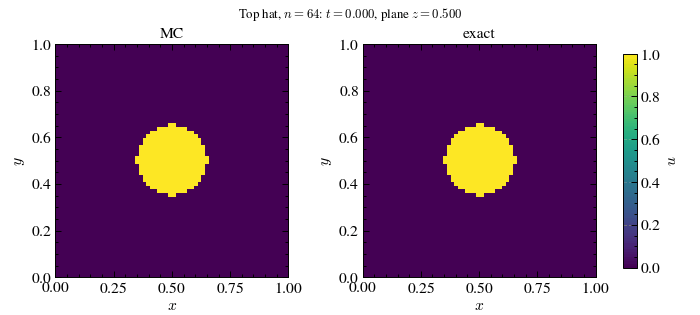

In [13]:
# Best limiter for the top hat: smallest E1 after one period at n = 64 (Godunov excluded)
limiter_names = [name for name in LAdvection3D.schemes() if name != "Godunov"]
best = min(limiter_names, key=lambda name: runs_1T["top hat"][name].errors()[0])
print("Best limiter for the top hat:", best)

# Advect the top hat for one period at n = 64, one frame every 4 steps
anim3d = LAdvection3D.animate(best, n=64, cfl=0.4, steps_per_frame=4)

# Save the GIF
anim3d.save("tophat3d_best_limiter.gif", writer=PillowWriter(fps=10), dpi=70)

# Show the GIF
if os.path.exists("tophat3d_best_limiter.gif"):
    display(Image(filename="tophat3d_best_limiter.gif"))

MC keeps the profile at $u = 1$ and stays within $[0, 1]$, but it's also diffused over a few cells. The profile stays nearly round, so the splitting does not visibly distort its shape at this resolution.